Para definir correatmente o valor de k, dias metricas devem ser testadas,
* A tecnicado cotovelo: A **inércia** é a soma das distâncias quadráticas de cada ponto ao centro do seu cluster (também conhecida como WCSS - Within-Cluster Sum of Squares). Procuramos o ponto no gráfico (o "cotovelo") onde a diminuição da inércia começa a se tornar marginal. Adicionar mais um cluster depois desse ponto não melhora significativamente a variância total explicada.

* A Análise de Silueta mede o quão bem um objeto se encaixa em seu próprio cluster (coesão) em comparação com o cluster mais próximo (separação).

O coeficiente de silueta varia de -1 a +1:

+1: O ponto está perfeitamente agrupado (longe dos clusters vizinhos).

0: O ponto está no limite entre dois clusters.

-1: O ponto provavelmente foi atribuído ao cluster errado.

Procuramos o valor de k que maximiza o coeficiente de silueta médio para todo o conjunto de dados.

/tmp/ipykernel_2812/3654171574.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


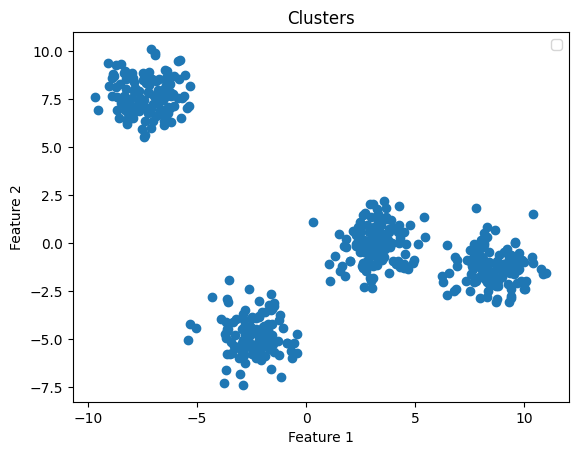

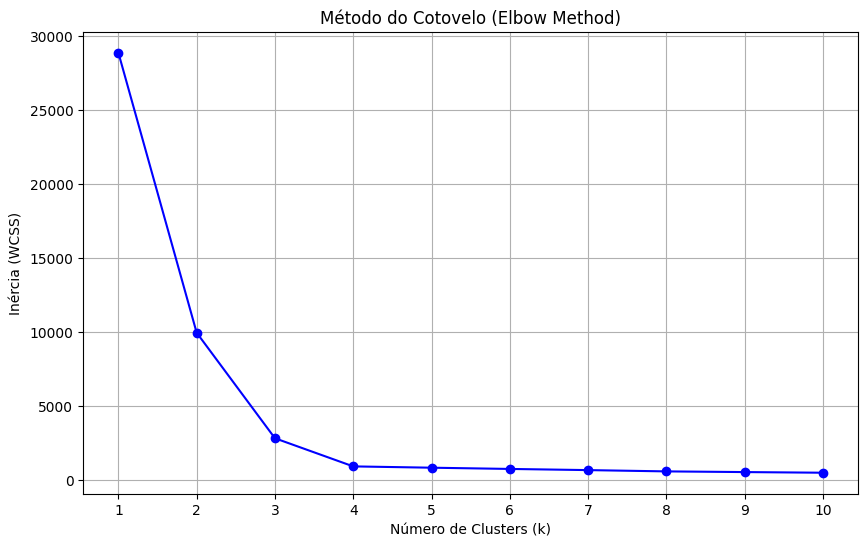

In [ ]:
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# Gerar dados de exemplo
# Vamos criar 4 "bolhas" de dados
X, y = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=2025)

# Visualização dos Clusters
plt.scatter(X[:, 0], X[:, 1])

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Clusters')
plt.legend()
plt.show()

#Implementa o Método do Cotovelo
wcss = [] # Lista para armazenar a inércia (WCSS) para cada k
k_range = range(1, 11) # Testar de 1 a 10 clusters

for k in k_range:
    kmeans = KMeans(n_clusters=k,
                    init='k-means++', # Inicialização inteligente
                    n_init=10,       # Rodar 10x com centroides diferentes
                    max_iter=300,    # Máximo de iterações por rodada
                    random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# 3. Plotar o gráfico do cotovelo
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, 'bo-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia (WCSS)')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

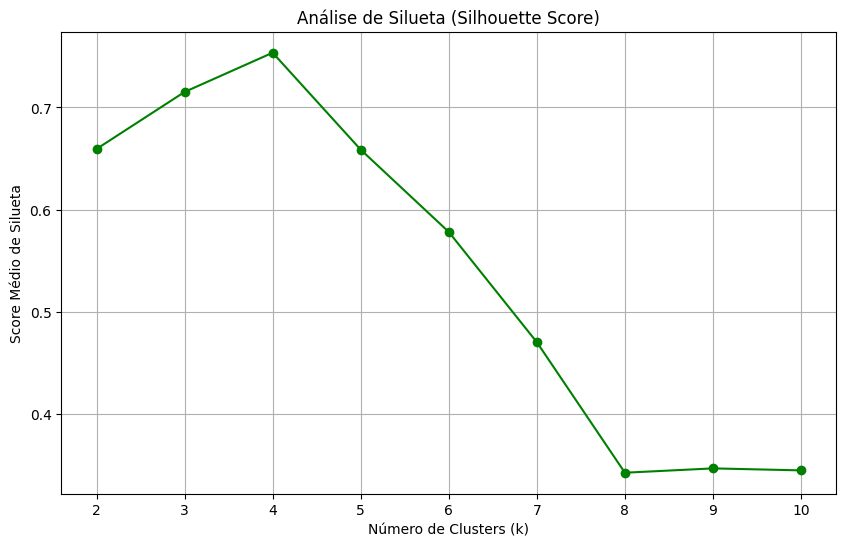

In [ ]:
from sklearn.metrics import silhouette_score

# Usamos os mesmos dados 'X' da etapa anterior

# Implementar a Análise de Silueta
silhouette_scores = []
k_range_silhouette = range(2, 11) # Silueta requer pelo menos 2 clusters

for k in k_range_silhouette:
    kmeans = KMeans(n_clusters=k,
                    init='k-means++',
                    n_init=10,
                    max_iter=300,
                    random_state=42)
    kmeans.fit(X)

    # Obter os rótulos (a qual cluster cada ponto pertence)
    labels = kmeans.labels_

    # Calcula o score de silueta médio
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

#  Plotar o gráfico de Silueta
plt.figure(figsize=(10, 6))
plt.plot(k_range_silhouette, silhouette_scores, 'go-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Score Médio de Silueta')
plt.title('Análise de Silueta (Silhouette Score)')
plt.xticks(k_range_silhouette)
plt.grid(True)
plt.show()

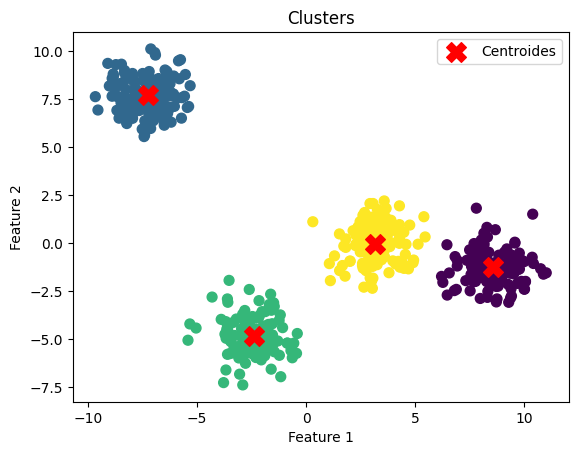

In [ ]:
from sklearn.cluster import KMeans

kmeans_sklearn = KMeans(n_clusters=4, random_state=2025)
kmeans_sklearn.fit(X)

# Visualização dos Clusters
plt.scatter(X[:, 0], X[:, 1], c=kmeans_sklearn.labels_, cmap='viridis', s=50)
plt.scatter(kmeans_sklearn.cluster_centers_[:, 0], kmeans_sklearn.cluster_centers_[:, 1],
            s=200, c='red', marker='X', label='Centroides')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Clusters')
plt.legend()
plt.show()

Atividade: vamos ver se kmean consegue classificar corretamente os pinguins levando em conta 'bill_length_mm' e 'bill_depth_mm'

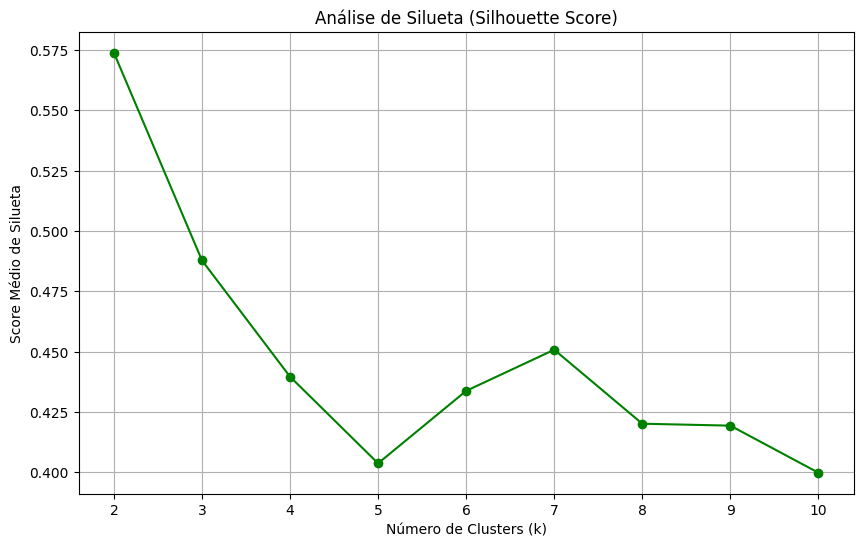

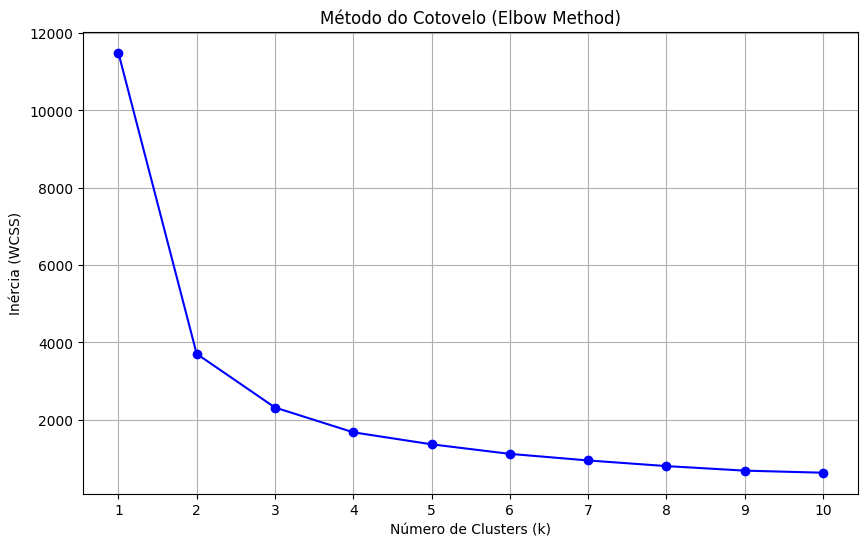

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv')

# Selecionar as colunas 'bill_length_mm' e 'bill_depth_mm' (índices 2 e 3)
X = df.iloc[:, 2:4]

# Remove linhas com valores NaN de X
X = X.dropna()

# Implementar a Análise de Silueta
silhouette_scores = []
k_range_silhouette = range(2, 11) # Silueta requer pelo menos 2 clusters

for k in k_range_silhouette:
    kmeans = KMeans(n_clusters=k,
                    init='k-means++',
                    n_init=10,
                    max_iter=300,
                    random_state=42)
    kmeans.fit(X)

    # Obter os rótulos (a qual cluster cada ponto pertence)
    labels = kmeans.labels_

    # Calcular o score de silueta médio
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

# Plotar o gráfico de Silueta
plt.figure(figsize=(10, 6))
plt.plot(k_range_silhouette, silhouette_scores, 'go-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Score Médio de Silueta')
plt.title('Análise de Silueta (Silhouette Score)')
plt.xticks(k_range_silhouette)
plt.grid(True)
plt.show()

# Implementar o Método do Cotovelo
wcss = [] # Lista para armazenar a inércia (WCSS) para cada k
k_range = range(1, 11) # Testar de 1 a 10 clusters

for k in k_range:
    kmeans = KMeans(n_clusters=k,
                    init='k-means++', # Inicialização inteligente
                    n_init=10,       # Rodar 10x com centroides diferentes
                    max_iter=300,    # Máximo de iterações por rodada
                    random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# 3. Plotar o gráfico do cotovelo
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, 'bo-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia (WCSS)')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

<Figure size 1000x600 with 0 Axes>

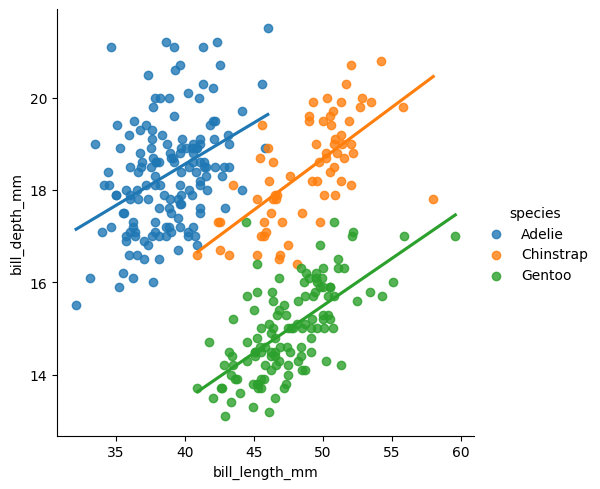

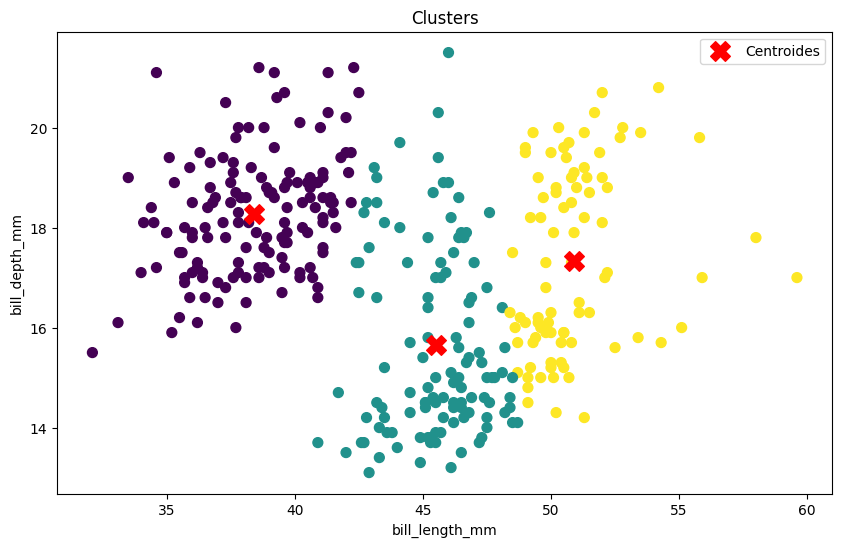

In [ ]:
import numpy as np
import seaborn as sns

# vermos com um regressão linear os valores exatos
plt.figure(figsize=(10, 6))
sns.lmplot(y='bill_depth_mm', x='bill_length_mm',hue='species', data=df, ci=None)

kmeans_sklearn = KMeans(n_clusters=3, random_state=2025)
kmeans_sklearn.fit(X)

# Visualização dos Clusters
plt.figure(figsize=(10, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=kmeans_sklearn.labels_, cmap='viridis', s=50)
plt.scatter(kmeans_sklearn.cluster_centers_[:, 0], kmeans_sklearn.cluster_centers_[:, 1],
            s=200, c='red', marker='X', label='Centroides')
plt.xlabel('bill_length_mm')
plt.ylabel('bill_depth_mm')
plt.title('Clusters')
plt.legend()
plt.show()

## Usando K-Means para Quantização de Cores em Imagens
Este notebook demonstra uma aplicação clássica do K-Means: a **quantização de cores**. O objetivo é reduzir o número de cores únicas em uma imagem para um número $k$, definido por nós.

 **Conceitos :**
 - **Dataset:** A imagem.
 - **Amostras (Pontos de Dados):** Cada pixel da imagem. Se a imagem tem 400x600 pixels, temos 240.000 amostras.
 - **Features (Características):** Os 3 canais de cor de cada pixel: **R** (Red), **G** (Green) e **B** (Blue). Nosso dataset terá a forma `(n_pixels, 3)`.
 - **Clusters ($k$):** O número de cores que queremos na imagem final.
 - **Centróides:** Os $k$ centróides encontrados pelo K-Means serão as $k$ cores (R,G,B) que formarão a "paleta" da nova imagem.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image # Para carregar uma imagem de exemplo
from sklearn.utils import shuffle # Para amostrar os pixels (opcional, mas bom para imagens grandes)

# Configurações de visualização
plt.rcParams['figure.figsize'] = (12, 8)

Carregando a imagem
 1.  Carregamos uma imagem de exemplo (neste caso, "china.jpg").
 2.  As imagens são carregadas como arrays NumPy no formato `(altura, largura, 3)`.
 3.  **Normalização:** Os valores dos pixels vêm como inteiros de 0 a 255. Para o K-Means funcionar bem, normalizamos esses valores para o intervalo [0, 1] dividindo por 255.
 4.  **Reshape (Reformatação):** O K-Means espera um array 2D na forma `(n_samples, n_features)`. Portanto, "achatamos" (flatten) a imagem de `(altura, largura, 3)` para `(altura * largura, 3)`.

In [ ]:
# Carregar a imagem de exemplo
# pode ser uma foto de sua escolha.
imagem_original = load_sample_image("flower.jpg") # outra opção "china.jpg"

# Converter de 0-255 (inteiros) para 0-1 (floats)
imagem_original = np.array(imagem_original, dtype=np.float64) / 255

# Obter as dimensões
altura, largura, canais = imagem_original.shape
print(f"Dimensões originais da imagem: {imagem_original.shape}")

# Reformatação: "achatar" a imagem para uma lista de pixels (n_pixels, 3)
# (altura, largura, 3) -> (altura * largura, 3)
dados_pixels = imagem_original.reshape(-1, canais)
print(f"Dimensões dos dados para o K-Means: {dados_pixels.shape}")

Dimensões originais da imagem: (427, 640, 3)
Dimensões dos dados para o K-Means: (273280, 3)


Treinamento do Modelo K-Means

 Vamos definir $k$ (o número de cores que queremos). Um valor como 16  já oferece uma boa compressão visual.

 *Nota para imagens grandes:* O dataset `dados_pixels` pode ser muito grande (milhões de pixels). Para acelerar o treinamento, é comum usar `MiniBatchKMeans` ou treinar em uma subamostra aleatória dos pixels (ex: `shuffle(dados_pixels, random_state=42)[:10000]`).

Por simplicidade, vamos usar o `KMeans` padrão nos dados completos, pois a imagem de exemplo não é tão grande.

In [ ]:
# Definir o número de cores (clusters)
k = 16



# Instanciar e treinar o modelo
kmeans = KMeans(n_clusters=k,
                n_init=10,        # Rodar 10x com centróides diferentes e escolher o melhor
                random_state=2024)

kmeans.fit(dados_pixels)



# Os centróides encontrados são a nossa nova paleta de cores
paleta_cores = kmeans.cluster_centers_

# O 'kmeans.labels_' nos diz a qual cluster (cor) cada pixel pertence
labels_pixels = kmeans.labels_

Reconstrução da Imagem

Agora, vamos criar a imagem comprimida:

Pegamos a paleta_cores (os centróides, shape (k, 3)).
Pegamos os labels_pixels (o cluster de cada pixel, shape (n_pixels,)).
Usamos os labels como um índice para "buscar" a cor correspondente na paleta.
Ex: paleta_cores[labels_pixels]
Isso cria um novo array (n_pixels, 3) onde cada pixel foi substituído pela cor do seu centróide.
Finalmente, reformatamos (reshape) o array de volta para as dimensões originais da imagem (altura, largura, 3).

Dimensões da imagem reconstruída: (427, 640, 3)


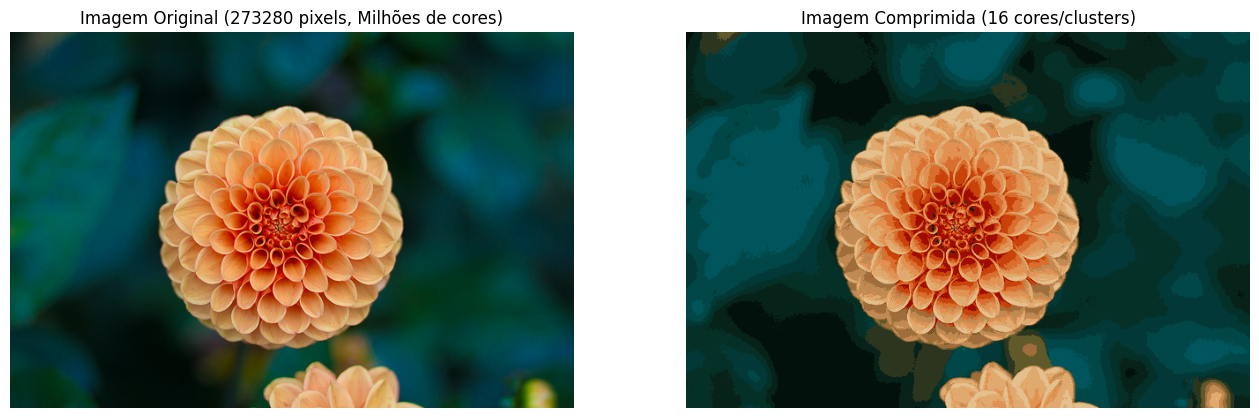

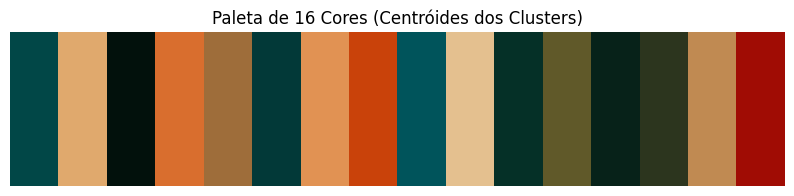

In [ ]:
# Cria a imagem comprimida "achatada" (flat)
# Cada pixel (índice i) recebe a cor do centróide do cluster ao qual pertence (labels_pixels[i])
imagem_comprimida_flat = paleta_cores[labels_pixels]

# Reformatação: voltar para as dimensões originais da imagem
# (n_pixels, 3) -> (altura, largura, 3)
imagem_comprimida = imagem_comprimida_flat.reshape(altura, largura, canais)

print(f"Dimensões da imagem reconstruída: {imagem_comprimida.shape}")


# Código de Visualização

# Plotar as Imagens Lado a Lado
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].imshow(imagem_original)
ax[0].set_title(f"Imagem Original ({altura*largura} pixels, Milhões de cores)")
ax[0].axis('off')

ax[1].imshow(imagem_comprimida)
ax[1].set_title(f"Imagem Comprimida ({k} cores/clusters)")
ax[1].axis('off')

plt.show()

# ploita Paleta de Cores
# Criamos uma "imagem" de 1 pixel de altura e 'k' pixels de largura
# O np.newaxis adiciona uma dimensão para que o imshow entenda
paleta_plot = paleta_cores[np.newaxis, :, :]

plt.figure(figsize=(10, 2))
plt.imshow(paleta_plot, aspect='auto')
plt.title(f"Paleta de {k} Cores (Centróides dos Clusters)")
plt.axis('off')
plt.show()

Atividade:

Troque de imagem para do seu time de footebol ou esporte favorito, defina um numero de cluster que representa seu time, por exemplo gremio que é tricolor k = 3.

Note que seria possivel desenvolver um classificador de imagens(definir qual a torcida) comparando as cores dos cluster (cores dominantes).